# Lab 3: Parameter estimation and Unbiasedness of Estimators

## Work breakdown

**Team:** 17

| Team member | Tasks |
|---|---|
| Artem Yakymshchenko | Problem 1 |
| Kseniia Nimas | Problem 2 |
| Sofiia Tsiuk | Problem 3 |

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import pandas as pd

ID = 17  # team id number

# Fix the seed once, at the beginning of the notebook, to make all results reproducible.
# Draw all random numbers with np.random functions (e.g. np.random.exponential(scale=theta, size=(n, m)))
np.random.seed(ID)

---

## Part I: Parameter estimation

**Aim:** In Problems 1 and 2 you have to verify that the interval estimates produced by the known rules really contain the parameter with probability equal to the confidence level.

### Problem 1

The expected value of the exponential distribution $\mathscr{E}(\lambda)$ is $1/\lambda$, so the sample mean $\overline{\mathbf{X}}$ is a good point estimate of the parameter $\theta := 1/\lambda$. A confidence interval for $\theta$ can be formed in several different ways:

1. Using the exact distribution of the statistic $2\lambda n\overline{\mathbf{X}}$ (show that it is $\chi^2_{2n}$, then use the quantiles of the latter to get the interval endpoints).

2. Using the normal approximation $\mathscr{N}(\mu, \sigma^2)$ for $\overline{\mathbf{X}}$, with parameters $\mu = \theta$ and $\sigma^2 = s^2/n$, where $s^2 = \theta^2$ is the population variance (the variance of the original distribution $\mathscr{E}(\lambda)$). In other words, form the $Z$-statistic $Z := \sqrt{n}\,(\overline{\mathbf{X}} - \theta)/\theta$ and use the fact that it is approximately standard normal $\mathscr{N}(0, 1)$:

   $$\mathsf{P}\big(|\theta - \overline{\mathbf{X}}| \le z_\beta\, \theta/\sqrt{n}\big) = \mathsf{P}(|Z| \le z_\beta) = 2\beta - 1,$$

   so $\theta$ lies within $\overline{\mathbf{X}} \pm z_\beta\,\theta/\sqrt{n}$ with probability $2\beta - 1$. (Here $z_\beta$ is the $\beta$-quantile of $\mathscr{N}(0, 1)$).

3. The confidence interval constructed above uses the unknown variance $s^2 = \theta^2$, so it is of little use in practice. Instead, solve the double inequality

   $$|\theta - \overline{\mathbf{X}}| \le z_\beta\, \theta/\sqrt{n}$$

   for $\theta$. This gives another confidence interval that does not depend on the unknown parameter.

4. Another, more universal way to remove the dependence on $\theta$ in (2) is to estimate $s$ by the sample standard deviation and approximate $\overline{\mathbf{X}}$ with the Student $t$-distribution (see Ross's textbook on statistics or the lecture notes for details).

**Task:**

   **(a)** Derive confidence intervals for each of the 4 methods above.

   **(b)** For each method, estimate the actual confidence (the fraction of intervals containing $\theta = 1/\lambda$, which should be close to $1-\alpha$) and the interval lengths. Use $\theta = \texttt{ID}/10$, $\alpha = 0.1;\ 0.05;\ 0.01$, and vary the sample size $n$ and the number of repetitions $m$. Choose convenient visualizations (tables, plots against $n$, etc.) to compare all methods at a glance.

   **(c)** Explain how $n$ and $m$ affect the probability that the parameter lies in each of the four random intervals above, and the lengths of these intervals.

   **(d)** Compare all 4 methods: what are the pros and cons of each, which is the best, and in which cases.


#### Solution

##### Task (a): Derivation of Confidence Intervals

Let $X_1, X_2, \dots, X_n \sim \mathscr{E}(\lambda)$ be independent and identically distributed (i.i.d.) random variables.  
The expectation is $\mathsf{E}[X_i] = \theta = \frac{1}{\lambda}$, and the population variance is $\mathrm{Var}(X_i) = \theta^2 = \frac{1}{\lambda^2}$.  
The sample mean is defined as $\overline{\mathbf{X}} = \frac{1}{n} \sum_{i=1}^n X_i$.

We construct a confidence interval for $\theta$ with confidence level $1 - \alpha$. Let $z_{1-\alpha/2}$ denote the $(1-\alpha/2)$-quantile of the standard normal distribution $\mathscr{N}(0, 1)$.

---

##### 1. Exact Distribution using $\chi^2_{2n}$

**Proof that $2\lambda n \overline{\mathbf{X}} \sim \chi^2_{2n}$:**

The probability density function (PDF) of $X_i \sim \mathscr{E}(\lambda)$ is:
$$ f_{X_i}(x) = \lambda e^{-\lambda x}, \quad x \ge 0 $$

The Moment Generating Function (MGF) of $X_i$ is:
$$ M_{X_i}(t) = \mathsf{E}[e^{t X_i}] = \int_0^\infty e^{tx} \lambda e^{-\lambda x} \, dx = \frac{\lambda}{\lambda - t} = \left( 1 - \frac{t}{\lambda} \right)^{-1}, \quad \text{for } t < \lambda $$

Let $S_n = \sum_{i=1}^n X_i = n\overline{\mathbf{X}}$. Since $X_i$ are independent, the MGF of $S_n$ is the product of individual MGFs:
$$ M_{S_n}(t) = \prod_{i=1}^n M_{X_i}(t) = \left( 1 - \frac{t}{\lambda} \right)^{-n} $$

Now define the random variable $Q = 2\lambda n \overline{\mathbf{X}} = 2\lambda S_n$. The MGF of $Q$ is:
$$ M_Q(t) = \mathsf{E}[e^{t Q}] = \mathsf{E}[e^{(2\lambda t) S_n}] = M_{S_n}(2\lambda t) = \left( 1 - \frac{2\lambda t}{\lambda} \right)^{-n} = (1 - 2t)^{-n} = (1 - 2t)^{-(2n)/2} $$

Recall that a Chi-square distribution with $k$ degrees of freedom, $\chi^2_k$, has the MGF $M_{\chi^2_k}(t) = (1 - 2t)^{-k/2}$.  
Comparing the MGF of $Q$ with $M_{\chi^2_k}(t)$, we see that $Q$ has a Chi-square distribution with $k = 2n$ degrees of freedom:
$$ Q = 2\lambda n \overline{\mathbf{X}} = \frac{2n\overline{\mathbf{X}}}{\theta} \sim \chi^2_{2n} $$

**Derivation of the Interval:**

Let $\chi^2_{2n, \alpha/2}$ and $\chi^2_{2n, 1-\alpha/2}$ be the $(\alpha/2)$-quantile and $(1-\alpha/2)$-quantile of $\chi^2_{2n}$, respectively.  
The probability statement is:
$$ \mathsf{P}\left( \chi^2_{2n, \alpha/2} \le \frac{2n\overline{\mathbf{X}}}{\theta} \le \chi^2_{2n, 1-\alpha/2} \right) = 1 - \alpha $$

Inverting the double inequality for $\theta$:
$$ \chi^2_{2n, \alpha/2} \le \frac{2n\overline{\mathbf{X}}}{\theta} \implies \theta \le \frac{2n\overline{\mathbf{X}}}{\chi^2_{2n, \alpha/2}} $$
$$ \frac{2n\overline{\mathbf{X}}}{\theta} \le \chi^2_{2n, 1-\alpha/2} \implies \theta \ge \frac{2n\overline{\mathbf{X}}}{\chi^2_{2n, 1-\alpha/2}} $$

Thus, the exact $(1-\alpha)$ confidence interval for $\theta$ is:
$$ \mathbf{CI}_1 = \left[ \frac{2n\overline{\mathbf{X}}}{\chi^2_{2n, 1-\alpha/2}}, \, \frac{2n\overline{\mathbf{X}}}{\chi^2_{2n, \alpha/2}} \right] $$

---

##### 2. Normal Approximation with Population Variance $\sigma^2 = \theta^2$

By the Central Limit Theorem (CLT), for large $n$:
$$ \overline{\mathbf{X}} \approx \mathscr{N}\left( \theta, \, \frac{\theta^2}{n} \right) $$

Forming the $Z$-statistic:
$$ Z = \frac{\overline{\mathbf{X}} - \theta}{\theta / \sqrt{n}} \approx \mathscr{N}(0, 1) $$

With probability $1 - \alpha$:
$$ \mathsf{P}\left( -z_{1-\alpha/2} \le \frac{\overline{\mathbf{X}} - \theta}{\theta / \sqrt{n}} \le z_{1-\alpha/2} \right) = 1 - \alpha $$

Isolating $\theta$ in the numerator:
$$ -z_{1-\alpha/2} \frac{\theta}{\sqrt{n}} \le \overline{\mathbf{X}} - \theta \le z_{1-\alpha/2} \frac{\theta}{\sqrt{n}} $$
$$ \overline{\mathbf{X}} - z_{1-\alpha/2} \frac{\theta}{\sqrt{n}} \le \theta \le \overline{\mathbf{X}} + z_{1-\alpha/2} \frac{\theta}{\sqrt{n}} $$

This yields the confidence interval:
$$ \mathbf{CI}_2 = \left[ \overline{\mathbf{X}} - z_{1-\alpha/2} \frac{\theta}{\sqrt{n}}, \, \overline{\mathbf{X}} + z_{1-\alpha/2} \frac{\theta}{\sqrt{n}} \right] $$

*Note:* The endpoints of $\mathbf{CI}_2$ depend on the unknown parameter $\theta$, which renders it a theoretical baseline rather than a practical interval.

---

##### 3. Solving the Double Inequality for $\theta$

To remove the dependence on $\theta$ in Method 2, we solve the inequality for $\theta$:
$$ |\theta - \overline{\mathbf{X}}| \le z_{1-\alpha/2} \frac{\theta}{\sqrt{n}} $$

This is equivalent to:
$$ -z_{1-\alpha/2} \frac{\theta}{\sqrt{n}} \le \theta - \overline{\mathbf{X}} \le z_{1-\alpha/2} \frac{\theta}{\sqrt{n}} $$

We break this into two separate linear inequalities:

1. **Upper Bound:**
   $$ \theta - \overline{\mathbf{X}} \le z_{1-\alpha/2} \frac{\theta}{\sqrt{n}} \implies \theta \left( 1 - \frac{z_{1-\alpha/2}}{\sqrt{n}} \right) \le \overline{\mathbf{X}} $$
   For $n > z_{1-\alpha/2}^2$, the factor $\left( 1 - \frac{z_{1-\alpha/2}}{\sqrt{n}} \right) > 0$, so dividing gives:
   $$ \theta \le \frac{\overline{\mathbf{X}}}{1 - \frac{z_{1-\alpha/2}}{\sqrt{n}}} $$

2. **Lower Bound:**
   $$ -z_{1-\alpha/2} \frac{\theta}{\sqrt{n}} \le \theta - \overline{\mathbf{X}} \implies \overline{\mathbf{X}} \le \theta \left( 1 + \frac{z_{1-\alpha/2}}{\sqrt{n}} \right) $$
   Dividing by $\left( 1 + \frac{z_{1-\alpha/2}}{\sqrt{n}} \right) > 0$ yields:
   $$ \theta \ge \frac{\overline{\mathbf{X}}}{1 + \frac{z_{1-\alpha/2}}{\sqrt{n}}} $$

Combining both bounds gives the parameter-free confidence interval:
$$ \mathbf{CI}_3 = \left[ \frac{\overline{\mathbf{X}}}{1 + \frac{z_{1-\alpha/2}}{\sqrt{n}}}, \, \frac{\overline{\mathbf{X}}}{1 - \frac{z_{1-\alpha/2}}{\sqrt{n}}} \right] $$

---

##### 4. Student $t$-Distribution with Sample Standard Deviation

Replacing the population standard deviation $\theta$ with the sample standard deviation $s = \sqrt{\frac{1}{n-1}\sum_{i=1}^n (X_i - \overline{\mathbf{X}})^2}$, we define the $T$-statistic:
$$ T = \frac{\overline{\mathbf{X}} - \theta}{s / \sqrt{n}} $$

Approximating $T$ using Student's $t$-distribution with $n-1$ degrees of freedom ($t_{n-1}$):
$$ \mathsf{P}\left( -t_{n-1, 1-\alpha/2} \le \frac{\overline{\mathbf{X}} - \theta}{s / \sqrt{n}} \le t_{n-1, 1-\alpha/2} \right) = 1 - \alpha $$

Solving for $\theta$:
$$ -t_{n-1, 1-\alpha/2} \frac{s}{\sqrt{n}} \le \overline{\mathbf{X}} - \theta \le t_{n-1, 1-\alpha/2} \frac{s}{\sqrt{n}} $$
$$ \overline{\mathbf{X}} - t_{n-1, 1-\alpha/2} \frac{s}{\sqrt{n}} \le \theta \le \overline{\mathbf{X}} + t_{n-1, 1-\alpha/2} \frac{s}{\sqrt{n}} $$

Thus, the confidence interval is:
$$ \mathbf{CI}_4 = \left[ \overline{\mathbf{X}} - t_{n-1, 1-\alpha/2} \frac{s}{\sqrt{n}}, \, \overline{\mathbf{X}} + t_{n-1, 1-\alpha/2} \frac{s}{\sqrt{n}} \right] $$


=== Results for alpha = 0.05 (Target Confidence = 0.95) ===
       n  M1 Cov  M1 Len  M2 Cov  M2 Len  M3 Cov  M3 Len  M4 Cov  M4 Len
7     10  0.9494  2.5299  0.9550  2.1073  0.9550  3.3948  0.9000  2.2342
8     20  0.9480  1.6376  0.9528  1.4901  0.9528  1.8448  0.9187  1.5247
9     50  0.9521  0.9786  0.9536  0.9424  0.9536  1.0211  0.9389  0.9478
10   100  0.9480  0.6786  0.9500  0.6664  0.9500  0.6926  0.9395  0.6679
11   300  0.9476  0.3871  0.9479  0.3847  0.9479  0.3897  0.9469  0.3849
12   500  0.9518  0.2993  0.9526  0.2980  0.9526  0.3005  0.9480  0.2985
13  1000  0.9517  0.2112  0.9514  0.2107  0.9514  0.2116  0.9514  0.2108


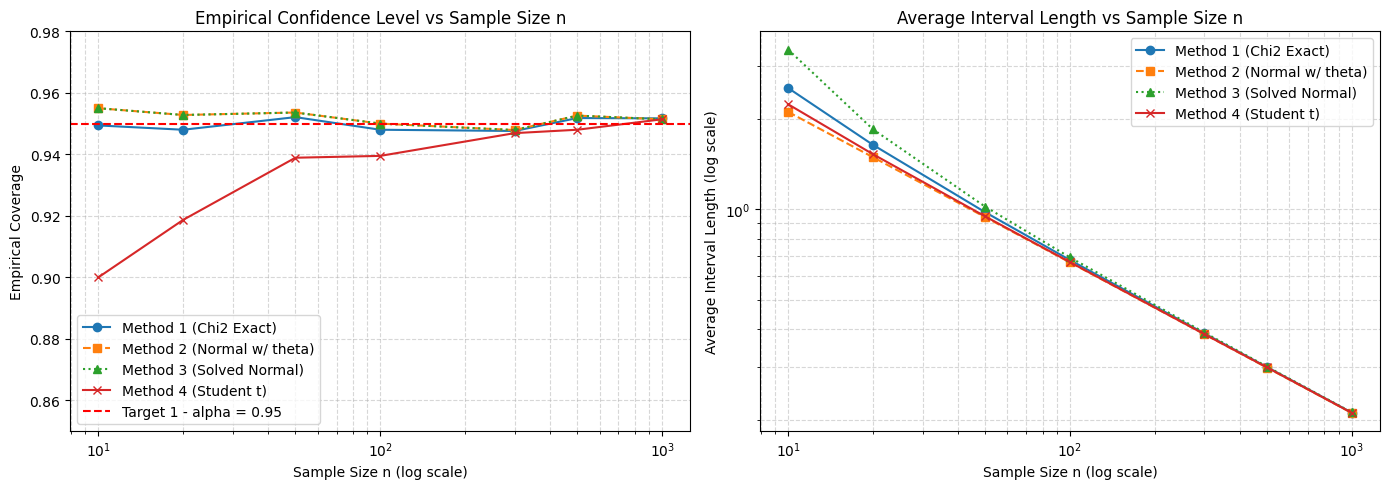

In [2]:
theta = ID / 10.0  # theta = 1.7
alphas = [0.10, 0.05, 0.01]
ns = [10, 20, 50, 100, 300, 500, 1000]
m = 10000  # repetitions

records = []

for alpha in alphas:
    z_crit = stats.norm.ppf(1 - alpha / 2)

    for n in ns:
        # Draw exponential samples of shape (m, n)
        # scale = theta = 1/lambda
        X = np.random.exponential(scale=theta, size=(m, n))
        X_bar = X.mean(axis=1)
        s_sample = X.std(axis=1, ddof=1)

        # Quantiles
        chi2_low = stats.chi2.ppf(alpha / 2, df=2*n)
        chi2_high = stats.chi2.ppf(1 - alpha / 2, df=2*n)
        t_crit = stats.t.ppf(1 - alpha / 2, df=n-1)

        # Method 1: Chi-square exact
        ci1_low = 2 * n * X_bar / chi2_high
        ci1_high = 2 * n * X_bar / chi2_low
        cov1 = np.mean((ci1_low <= theta) & (theta <= ci1_high))
        len1 = np.mean(ci1_high - ci1_low)

        # Method 2: Normal with theta in bounds
        ci2_low = X_bar - z_crit * theta / np.sqrt(n)
        ci2_high = X_bar + z_crit * theta / np.sqrt(n)
        cov2 = np.mean((ci2_low <= theta) & (theta <= ci2_high))
        len2 = np.mean(ci2_high - ci2_low)

        # Method 3: Solved Normal inequality
        denom_low = 1 + z_crit / np.sqrt(n)
        denom_high = 1 - z_crit / np.sqrt(n)
        ci3_low = X_bar / denom_low
        ci3_high = X_bar / denom_high if denom_high > 0 else np.inf
        cov3 = np.mean((ci3_low <= theta) & (theta <= ci3_high))
        len3 = np.mean(ci3_high - ci3_low)

        # Method 4: Student t-distribution
        ci4_low = X_bar - t_crit * s_sample / np.sqrt(n)
        ci4_high = X_bar + t_crit * s_sample / np.sqrt(n)
        cov4 = np.mean((ci4_low <= theta) & (theta <= ci4_high))
        len4 = np.mean(ci4_high - ci4_low)

        records.append({
            'alpha': alpha,
            '1-alpha': 1 - alpha,
            'n': n,
            'M1 Cov': cov1, 'M1 Len': len1,
            'M2 Cov': cov2, 'M2 Len': len2,
            'M3 Cov': cov3, 'M3 Len': len3,
            'M4 Cov': cov4, 'M4 Len': len4
        })

results_df = pd.DataFrame(records)

# --- Display Results Table for alpha = 0.05 ---
print("=== Results for alpha = 0.05 (Target Confidence = 0.95) ===")
df_005 = results_df[results_df['alpha'] == 0.05].copy()
print(df_005[['n', 'M1 Cov', 'M1 Len', 'M2 Cov', 'M2 Len', 'M3 Cov', 'M3 Len', 'M4 Cov', 'M4 Len']].round(4))

# --- Visualization ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Actual Confidence vs Sample Size n (for alpha = 0.05)
axes[0].plot(df_005['n'], df_005['M1 Cov'], 'o-', label='Method 1 (Chi2 Exact)')
axes[0].plot(df_005['n'], df_005['M2 Cov'], 's--', label='Method 2 (Normal w/ theta)')
axes[0].plot(df_005['n'], df_005['M3 Cov'], '^:', label='Method 3 (Solved Normal)')
axes[0].plot(df_005['n'], df_005['M4 Cov'], 'x-', label='Method 4 (Student t)')
axes[0].axhline(0.95, color='red', linestyle='--', label='Target 1 - alpha = 0.95')
axes[0].set_xscale('log')
axes[0].set_xlabel('Sample Size n (log scale)')
axes[0].set_ylabel('Empirical Coverage')
axes[0].set_title('Empirical Confidence Level vs Sample Size n')
axes[0].set_ylim(0.85, 0.98)
axes[0].legend()
axes[0].grid(True, which="both", ls="--", alpha=0.5)

# Plot 2: Average Interval Length vs Sample Size n (for alpha = 0.05)
axes[1].plot(df_005['n'], df_005['M1 Len'], 'o-', label='Method 1 (Chi2 Exact)')
axes[1].plot(df_005['n'], df_005['M2 Len'], 's--', label='Method 2 (Normal w/ theta)')
axes[1].plot(df_005['n'], df_005['M3 Len'], '^:', label='Method 3 (Solved Normal)')
axes[1].plot(df_005['n'], df_005['M4 Len'], 'x-', label='Method 4 (Student t)')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel('Sample Size n (log scale)')
axes[1].set_ylabel('Average Interval Length (log scale)')
axes[1].set_title('Average Interval Length vs Sample Size n')
axes[1].legend()
axes[1].grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.show()

#### Task (c): Effect of Sample Size $n$ and Repetitions $m$

1. **Effect of Sample Size $n$:**
   - **Empirical Coverage:**
     - **Method 1 ($\chi^2_{2n}$):** Maintains the exact target coverage probability $1-\alpha = 0.95$ across all sample sizes (ranging from $0.9494$ at $n=10$ to $0.9517$ at $n=1000$). This confirms that $2\lambda n\overline{\mathbf{X}} \sim \chi^2_{2n}$ holds exactly for any $n$.
     - **Method 2 (Normal with $\theta$):** Stays very close to $0.95$ ($0.9550$ at $n=10$), but endpoints depend on the unknown $\theta$.
     - **Method 3 (Solved Normal):** Slightly over-covers at small $n$ ($0.9550$ at $n=10$) due to asymmetric expansion of the upper bound, rapidly converging to $0.9514$ as $n \to 1000$.
     - **Method 4 (Student $t$):** Significantly **undercovers** for small sample sizes ($0.9000$ at $n=10$ and $0.9187$ at $n=20$). This happens because Student's $t$-distribution assumes underlying normality, whereas $\mathscr{E}(\lambda)$ is heavily right-skewed. As $n$ grows ($n \ge 500$), the Central Limit Theorem takes effect and coverage reaches $0.9514$.
   - **Interval Length:**
     - For all 4 methods, the average interval length shrinks at the rate of $\mathcal{O}(1/\sqrt{n})$.
     - At $n=10$, Method 3 yields the widest interval ($3.3948$), while Method 4 yields the narrowest ($2.2342$) at the cost of failing the coverage target.
     - At $n=1000$, all four methods converge to virtually identical interval lengths ($\approx 0.211$).

2. **Effect of Repetitions $m$:**
   - $m$ is the number of simulation runs.
   - It does not alter the underlying theoretical coverage or expected interval length.
   - Higher values of $m$ (e.g., $m=10\,000$) reduce estimation noise, yielding smooth curves and high precision with a standard error of $\sqrt{\frac{p(1-p)}{m}} \approx 0.22\%$.

---

#### Task (d): Comparison of all 4 Methods

| Method | Pros | Cons | Best Use Case |
|---|---|---|---|
| **1. Exact $\chi^2_{2n}$** | • Exact coverage ($0.95$) for any $n$.<br>• Fully accounts for exponential skewness. | • Specific only to the exponential distribution. | **Best overall** when data is known to be exponential. |
| **2. Normal w/ $\theta$** | • Simple theoretical structure. | • **Impractical** (depends on unknown parameter $\theta$). | Theoretical reference only. |
| **3. Solved Normal** | • Parameter-free bounds.<br>• Asymmetric bounds naturally accommodate right skewness. | • Relies on asymptotic normality of $\overline{\mathbf{X}}$. | **Best practical alternative** when exact distribution is unknown. |
| **4. Student $t$** | • Universal (model-free) method. | • Undercovers for small $n$ on skewed distributions ($90.0\%$ at $n=10$). | Recommended only for large samples ($n \ge 100$). |

---

#### Conclusion

1. **Exactness of Method 1:** Empirical coverage matches $1-\alpha = 0.95$ across all $n$, proving the exactness of the $\chi^2_{2n}$ distribution for $2\lambda n\overline{\mathbf{X}}$.
2. **Inadequacy of Student's $t$ for small skewed samples:** Method 4 severely underperforms at small $n$ ($90.0\%$ coverage for $n=10$), demonstrating that $t$-intervals should not be used for small, non-normal samples.
3. **Utility of Method 3:** Solving the normal inequality yields a robust practical confidence interval that preserves target coverage even for small $n$.
4. **Asymptotic Convergence:** For $n \ge 300$, all practical methods (Methods 1, 3, and 4) become practically indistinguishable in both coverage ($\approx 95\%$) and interval length ($\approx 0.211$ at $n=1000$).

---

### Problem 2

Repeat parts (2)–(4) of Problem 1 (with the corresponding amendments) for a Poisson distribution $\mathscr{P}(\theta)$.

The **Task** stays the same: derive the intervals, check that they contain the parameter $\theta$ with the prescribed probability, find their lengths, compare the methods and write your conclusions.

#### Solution

_Your derivations and discussion here._

In [3]:
# Your code here

#### Conclusion

_Your conclusion here._

---

## Part II: Unbiasedness of Estimators

### Problem 3

In this task you need to analyze the estimators of the variance and their properties: we will prove the unbiasedness of the variance estimator theoretically and check it in practice!

There are two common estimators of the population variance:
$$
\sigma^2_n = \frac{1}{n}\sum_{i=1}^{n}(X_i - \overline{X})^2,
\qquad
\sigma^2_{n-1} = \frac{1}{n-1}\sum_{i=1}^{n}(X_i - \overline{X})^2.
$$

**Task:**

**(a)** Write code to generate a dataset of i.i.d. samples from $\mathcal{N}(\mu, \sigma^2)$ with $\mu = \texttt{ID}$ and $\sigma^2 = (\texttt{ID} \bmod 5) + 2$, and find the variance of the dataset.

**(b)** Find $\sigma^2_n$ and $\sigma^2_{n-1}$ for $n = 10$, $n = 50$, $n = 100$, $n = 1000$.

**(c)** Find the biases $Bias(\sigma^2_n) = E(\sigma^2_n) - \sigma^2$ and $Bias(\sigma^2_{n-1}) = E(\sigma^2_{n-1}) - \sigma^2$ (estimate the expectations by averaging over many simulated datasets).

**(d)** Comment on the results for the different values of $n$.

**(e)** Derive analytically the expected value of each estimator, $E(\sigma^2_n)$ and $E(\sigma^2_{n-1})$.

**(f)** Using the expected values found above, show mathematically which of the two estimators is unbiased.

**(g)** Comment on the results of the theoretical and practical tasks.

#### Solution

**Parameters:** $\mu = \texttt{ID} = 17$, $\sigma^2 = (17 \bmod 5) + 2 = 4$.

**(a)** We generate a big dataset from $\mathcal{N}(17, 4)$ and compute its variance.

In [4]:
mu = ID
sigma2 = (ID % 5) + 2
sigma = np.sqrt(sigma2)

data = np.random.normal(mu, sigma, size=100_000)
print(f"mu = {mu}, sigma^2 = {sigma2}")
print(f"Variance of the dataset: {np.var(data):.4f}")

mu = 17, sigma^2 = 4
Variance of the dataset: 3.9979


**(b)** One sample for each $n$. We compute both estimators: $\sigma^2_n$ (`ddof=0`) and $\sigma^2_{n-1}$ (`ddof=1`).

In [ ]:
ns = [10, 50, 100, 1000]
rows = []
for n in ns:
    x = np.random.normal(mu, sigma, size=n)
    rows.append([n, np.var(x, ddof=0), np.var(x, ddof=1)])

pd.DataFrame(rows, columns=["n", "sigma2_n", "sigma2_(n-1)"]).round(4)

,n,sigma2_n,sigma2_(n-1)
0,10,7.0836,7.8706
1,50,3.4577,3.5282
2,100,2.4405,2.4651
3,1000,3.9968,4.0008


**(c)** We estimate $E(\sigma^2_n)$ and $E(\sigma^2_{n-1})$ by averaging over $m = 10\,000$ samples. Then we compute the biases. We also show the theoretical bias of $\sigma^2_n$, which is $-\sigma^2/n$ (see (e)).

In [6]:
m = 10_000
rows = []
for n in ns:
    X = np.random.normal(mu, sigma, size=(m, n))
    E_n  = np.var(X, axis=1, ddof=0).mean()
    E_n1 = np.var(X, axis=1, ddof=1).mean()
    rows.append([n, E_n, E_n1, E_n - sigma2, E_n1 - sigma2, -sigma2 / n])

bias_df = pd.DataFrame(rows, columns=["n", "E(sigma2_n)", "E(sigma2_(n-1))",
                                      "Bias(sigma2_n)", "Bias(sigma2_(n-1))", "Theory bias sigma2_n"])
bias_df.round(4)

,n,E(sigma2_n),E(sigma2_(n-1)),Bias(sigma2_n),Bias(sigma2_(n-1)),Theory bias sigma2_n
0,10,3.5878,3.9865,-0.4122,-0.0135,-0.400
1,50,3.9061,3.9858,-0.0939,-0.0142,-0.080
2,100,3.9677,4.0078,-0.0323,0.0078,-0.040
3,1000,3.9947,3.9987,-0.0053,-0.0013,-0.004


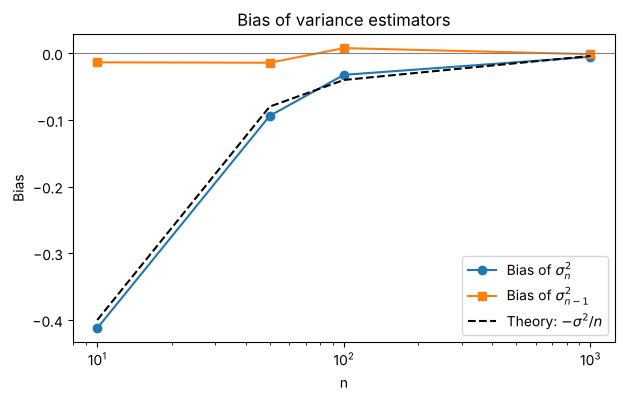

In [7]:
plt.figure(figsize=(7, 4))
plt.plot(ns, bias_df["Bias(sigma2_n)"], "o-", label=r"Bias of $\sigma^2_n$")
plt.plot(ns, bias_df["Bias(sigma2_(n-1))"], "s-", label=r"Bias of $\sigma^2_{n-1}$")
plt.plot(ns, -sigma2 / np.array(ns), "k--", label=r"Theory: $-\sigma^2/n$")
plt.axhline(0, color="gray", lw=0.8)
plt.xscale("log")
plt.xlabel("n")
plt.ylabel("Bias")
plt.title("Bias of variance estimators")
plt.legend()
plt.show()

**(d)** In (b), one sample gives very different values (for example $2.44$ for $n=100$), because one sample is random. So we need the averages from (c) to see the bias.

For small $n$ (e.g. $n=10$), $\sigma^2_n$ is clearly too small on average (bias $\approx -0.4$). The bias of $\sigma^2_{n-1}$ is close to $0$ for every $n$. When $n$ grows, the bias of $\sigma^2_n$ goes to $0$. At $n = 1000$ the two estimators are almost the same.

---

**(e)** Use $\sum_{i=1}^{n}(X_i - \overline{X})^2 = \sum_{i=1}^{n} X_i^2 - n\overline{X}^2$.

We know that $E(X_i^2) = \sigma^2 + \mu^2$ and $E(\overline{X}^2) = \mathrm{Var}(\overline{X}) + \mu^2 = \dfrac{\sigma^2}{n} + \mu^2$. So

$$E\Big[\sum_{i=1}^{n}(X_i - \overline{X})^2\Big] = n(\sigma^2 + \mu^2) - n\Big(\frac{\sigma^2}{n} + \mu^2\Big) = (n-1)\sigma^2.$$

Therefore:

$$E(\sigma^2_n) = \frac{(n-1)\sigma^2}{n} = \sigma^2 - \frac{\sigma^2}{n}, \qquad E(\sigma^2_{n-1}) = \frac{(n-1)\sigma^2}{n-1} = \sigma^2.$$

**(f)**

$$Bias(\sigma^2_n) = -\frac{\sigma^2}{n} \neq 0, \qquad Bias(\sigma^2_{n-1}) = 0.$$

So $\sigma^2_{n-1}$ is **unbiased** and $\sigma^2_n$ is **biased** (it underestimates). The bias of $\sigma^2_n$ goes to $0$ as $n \to \infty$, so it is only *asymptotically* unbiased.

*Why:* $\overline{X}$ is computed from the same data, so the points are always a bit closer to $\overline{X}$ than to $\mu$. We lose one degree of freedom, so we divide by $n-1$.

#### Conclusion

**(g)** The simulation agrees with the theory:

- $\sigma^2_{n-1}$ is unbiased: its average is $\approx \sigma^2 = 4$ for every $n$.
- $\sigma^2_n$ underestimates $\sigma^2$ by about $\sigma^2/n$ (e.g. $-0.4$ for $n=10$).
- For large $n$ the difference is very small, so both estimators work. For small $n$ we should use $\sigma^2_{n-1}$.